<a href="https://colab.research.google.com/github/swethas-22/Matplotlib_Seaborn_Project/blob/main/Matplotlib_Seaborn_Tips_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_812/3201769293.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_812/3201769293.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


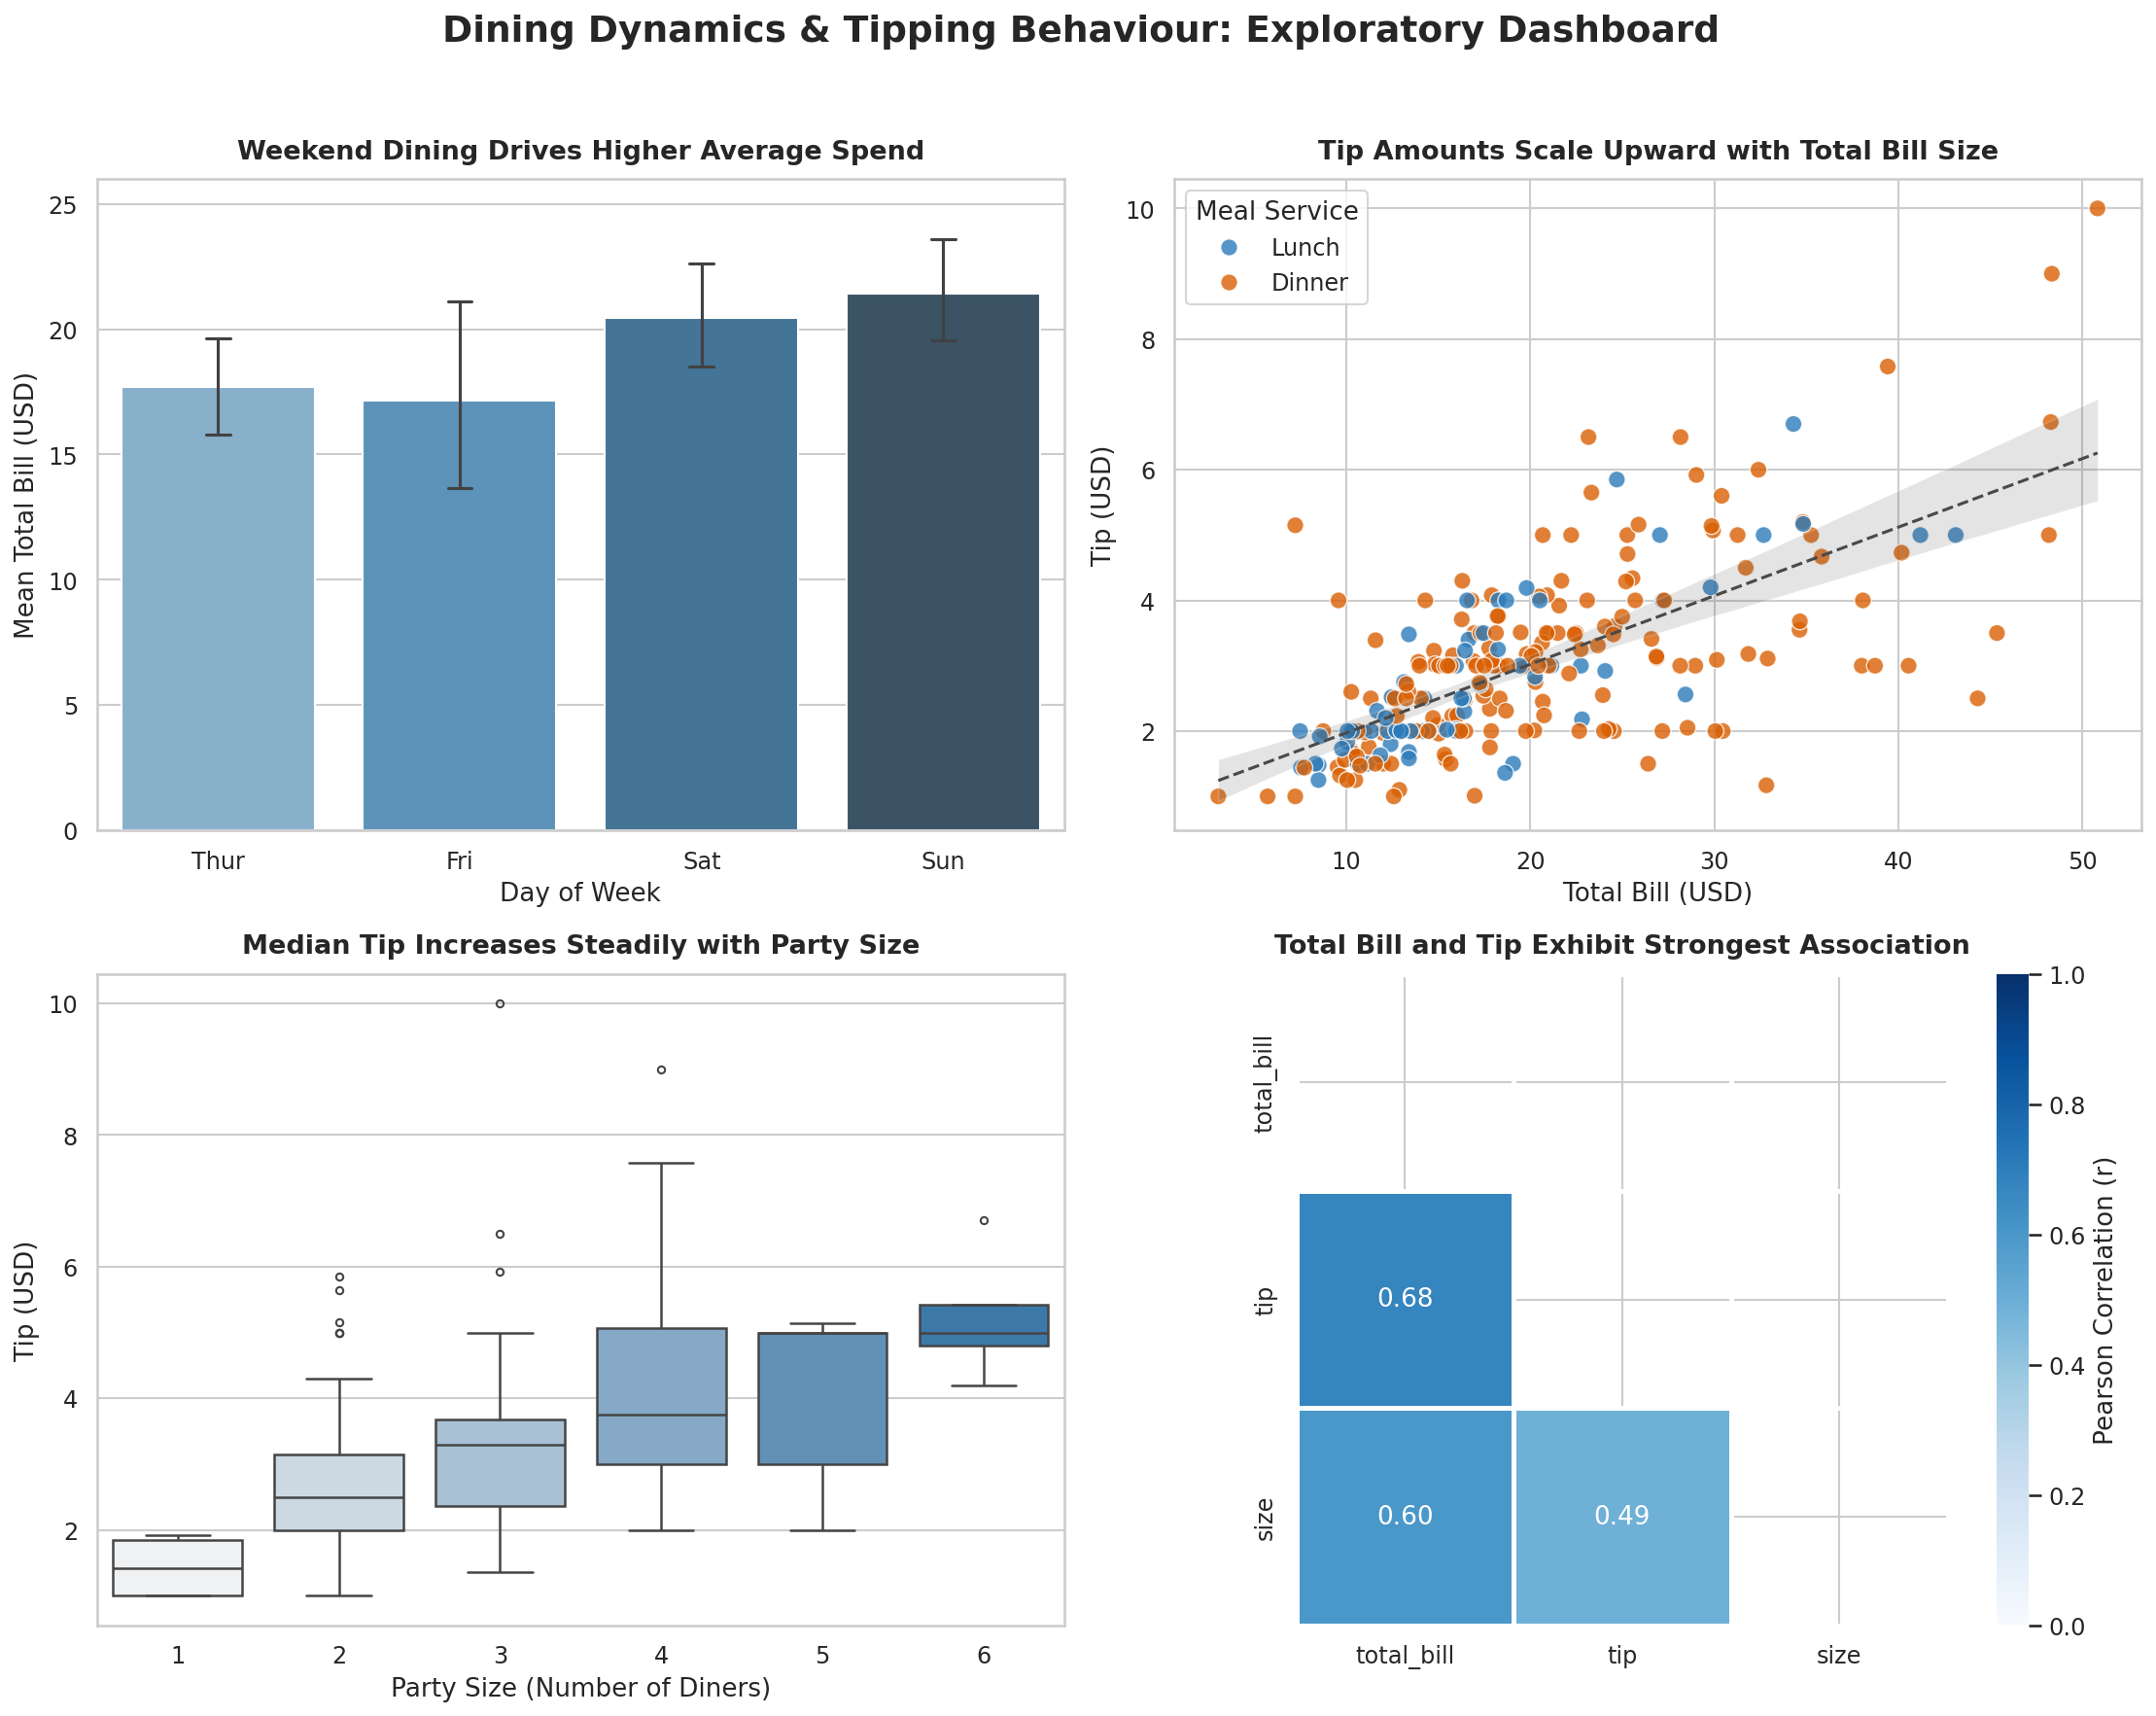

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid", font_scale=1.05)

# Load the dataset
tips = sns.load_dataset("tips")

# Create the 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12), dpi=150)
fig.suptitle(
    "Dining Dynamics & Tipping Behaviour: Exploratory Dashboard",
    fontsize=18,
    fontweight="bold",
    y=0.98,
)

# 1. Bar Chart: Average Bill by Day
sns.barplot(
    data=tips,
    x="day",
    y="total_bill",
    order=["Thur", "Fri", "Sat", "Sun"],
    palette="Blues_d",
    ax=axes[0, 0],
    capsize=0.1,
    err_kws={"linewidth": 1.5},
)
axes[0, 0].set_title(
    "Weekend Dining Drives Higher Average Spend", fontsize=13, fontweight="semibold", pad=10
)
axes[0, 0].set_xlabel("Day of Week")
axes[0, 0].set_ylabel("Mean Total Bill (USD)")
axes[0, 0].set_ylim(0, 26)

# 2. Scatter Plot: Bill vs Tip
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    palette={"Lunch": "#2b7bba", "Dinner": "#d95f02"},
    alpha=0.8,
    s=70,
    ax=axes[0, 1],
)
sns.regplot(
    data=tips,
    x="total_bill",
    y="tip",
    scatter=False,
    ax=axes[0, 1],
    color="#4a4a4a",
    line_kws={"linestyle": "--", "linewidth": 1.5},
)
axes[0, 1].set_title(
    "Tip Amounts Scale Upward with Total Bill Size", fontsize=13, fontweight="semibold", pad=10
)
axes[0, 1].set_xlabel("Total Bill (USD)")
axes[0, 1].set_ylabel("Tip (USD)")
axes[0, 1].legend(title="Meal Service")

# 3. Box Plot: Tip by Party Size
sns.boxplot(
    data=tips,
    x="size",
    y="tip",
    palette="light:#2b7bba",
    ax=axes[1, 0],
    fliersize=3.5,
    linewidth=1.2,
)
axes[1, 0].set_title(
    "Median Tip Increases Steadily with Party Size", fontsize=13, fontweight="semibold", pad=10
)
axes[1, 0].set_xlabel("Party Size (Number of Diners)")
axes[1, 0].set_ylabel("Tip (USD)")

# 4. Correlation Heatmap
corr_matrix = tips.select_dtypes(include="number").corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation (r)"},
    ax=axes[1, 1],
    linewidths=1.5,
    square=True,
)
axes[1, 1].set_title(
    "Total Bill and Tip Exhibit Strongest Association", fontsize=13, fontweight="semibold", pad=10
)

# Export and display
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("tips_data_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## Key Takeaways

1. **Bar Chart (Spend by Day):** Sunday records the highest average spend per table ($21.41), with weekend dinners systematically outpacing Thursday and Friday lunch-driven bills.
2. **Scatter Plot (Bill vs. Tip):** Tips increase proportionally with total spending (r ≈ 0.68), with dinner patrons accounting for both the highest bills and the highest tips.
3. **Box Plot (Tip by Party Size):** Median tip amounts increase steadily from 1-person parties ($1.83) up to 4-person groups ($4.00), while variance widens for groups of 5 and 6.
4. **Correlation Heatmap:** The strongest relationship across the dataset exists between total bill and tip (r = 0.68), while party size has a moderate association with total spend (r = 0.60).